# Final Project

This final project can be collaborative. The maximum members of a group is 3. You can also work by yourself. Please respect the academic integrity. **Remember: if you get caught on cheating, you get F.**

## A Introduction to the competition

<img src="news-sexisme-EN.jpg" alt="drawing" width="380"/>

Sexism is a growing problem online. It can inflict harm on women who are targeted, make online spaces inaccessible and unwelcoming, and perpetuate social asymmetries and injustices. Automated tools are now widely deployed to find, and assess sexist content at scale but most only give classifications for generic, high-level categories, with no further explanation. Flagging what is sexist content and also explaining why it is sexist improves interpretability, trust and understanding of the decisions that automated tools use, empowering both users and moderators.

This project is based on SemEval 2023 - Task 10 - Explainable Detection of Online Sexism (EDOS). [Here](https://codalab.lisn.upsaclay.fr/competitions/7124#learn_the_details-overview) you can find a detailed introduction to this task.

You only need to complete **TASK A - Binary Sexism Detection: a two-class (or binary) classification where systems have to predict whether a post is sexist or not sexist**. To cut down training time, we only use a subset of the original dataset (5k out of 20k). The dataset can be found in the same folder. 

Different from our previous homework, this competition gives you great flexibility (and very few hints). You can freely determine every component of your workflow, including but not limited to:
-  **Preprocessing the input text**: You may decide how to clean or transform the text. For example, removing emojis or URLs, lowercasing, removing stopwords, applying stemming or lemmatization, correcting spelling, or performing tokenization and sentence segmentation.
-  **Feature extraction and encoding**: You can choose any method to convert text into numerical representations, such as TF-IDF, Bag-of-Words, N-grams, Word2Vec, GloVe, FastText, contextual embeddings (e.g., BERT, RoBERTa, or other transformer-based models), Part-of-Speech (POS) tagging, dependency-based features, sentiment or emotion features, readability metrics, or even embeddings or features generated by large language models (LLMs).
-  **Data augmentation and enrichment**: You may expand or balance your dataset by incorporating other related corpora or using techniques like synonym replacement, random deletion/insertion, or LLM-assisted augmentation (e.g., generating paraphrased or synthetic examples to improve model robustness).
-  **Model selection**: You are free to experiment with different models — from traditional machine learning algorithms (e.g., Logistic Regression, SVM, Random Forest, XGBoost) to deep learning architectures (e.g., CNNs, RNNs, Transformers), or even hybrid/ensemble approaches that combine multiple models or leverage LLM-generated predictions or reasoning.

## Requirements
-  **Input**: the text for each instance.
-  **Output**: the binary label for each instance.
-  **Feature engineering**: use at least 2 different methods to extract features and encode text into numerical values. You may explore both traditional and AI-assisted techniques. Data augmentation is optional.
-  **Model selection**: implement with at least 3 different models and compare their performance.
-  **Evaluation**: create a dataframe with rows indicating feature+model and columns indicating Precision (P), Recall (R) and F1-score (using weighted average). Your results should have at least 6 rows (2 feature engineering methods x 3 models). Report best performance with (1) your feature engineering method, and (2) the model you choose. Here is an example illustrating how the experimental results table should be presented.

| Feature + Model | Sexist (P) | Sexist (R) | Sexist (F1) | Non-Sexist (P) | Non-Sexist (R) | Non-Sexist (F1) | Weighted (P) | Weighted (R) | Weighted (F1) |
|-----------------|:----------:|:----------:|:------------:|:---------------:|:---------------:|:----------------:|:-------------:|:--------------:|:---------------:|
| TF-IDF + Logistic Regression | ... | ... | ... | ... | ... | ... | ... | ... | ... |

- **Format of the report**: add explainations for each step (you can add markdown cells). At the end of the report, write a summary for each sections: 
    - Data Preprocessing
    - Feature Engineering
    - Model Selection and Architecture
    - Training and Validation
    - Evaluation and Results
    - Use of Generative AI (if you use)

## Rules 
Violations will result in 0 points in the grade: 
-   `Rule 1 - No test set leakage`: You must not use any instance from the test set during training, feature engineering, or model selection.
-   `Rule 2 - Responsible AI use`: You may use generative AI, but you must clearly document how it was used. If you have used genAI, include a section titled “Use of Generative AI” describing:
    -   What parts of the project you used AI for
    -   What was implemented manually vs. with AI assistance

## Grading

The performance should be only evaluated on the test set (a total of 1086 instances). Please split original dataset into train set and test set. The test set should NEVER be used in the training process. The evaluation metric is a combination of precision, recall, and f1-score (use `classification_report` in sklearn). 

The total points are 10.0. Each team will compete with other teams in the class on their best performance. Points will be deducted if not following the requirements above. 

If ALL the requirements are met:
- Top 25\% teams: 10.0 points.
- Top 25\% - 50\% teams: 8.5 points.
- Top 50\% - 75\% teams: 7.0 points.
- Top 75\% - 100\% teams: 6.0 points.

If your best performance reaches **0.82** or above (weighted F1-score) and follows all the requirements and rules, you will also get full points (10.0 points). 

## Submission
Similar as homework, submit both a PDF and .ipynb version of the report including: 
- code and experimental results with details explained
- combined results table, report and best performance
- a summary at the end of the report (please follow the format above)

Missing any part of the above requirements will result in point deductions.

The due date is **May 8, Friday by 11:59pm**.

# Final Project Information
Author: Eric Romero
Course: CSC 380
Due Date: May 8, 2026

In [24]:
# start your code here
import pandas as pd 
import numpy as np 
from sklearn.feature_extraction.text import CountVectorizer 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC 
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

import matplotlib.pyplot as plt

# Data Exploration
Before building any models, I first looked at the dataset itself. The file contains 5279 total posts, with four columns: `rewire_id`, `text`, `label`, and `split`. The important columns for this project are `text`, which contains the post, and `label`, which tells us whether the post is `sexist` or `not sexist`. The dataset is already divided into a training set and a test set. There are 4193 training examples and 1086 test examples. I kept this split exactly as given so that the test set stayed untouched until evaluation. The label distribution is also important. There are more `not sexist` posts than `sexist` posts, so the dataset is not perfectly balanced. That means a model could look decent overall while still missing a lot of sexist content. For this kind of task, that matters. The whole point is not just to classify the easy cases, but to catch the uglier posts too.

In [25]:
data = pd.read_csv("edos_labelled_data.csv")
display(data.head())

,rewire_id,text,label,split
0,sexism2022_english-9609,"In Nigeria, if you rape a woman, the men rape ...",not sexist,train
1,sexism2022_english-16993,"Then, she's a keeper. 😉",not sexist,train
2,sexism2022_english-13149,This is like the Metallica video where the poo...,not sexist,train
3,sexism2022_english-13021,woman?,not sexist,train
4,sexism2022_english-966,I bet she wished she had a gun,not sexist,train


In [26]:
print(data.shape)
print(data.columns)
print(data["label"].value_counts())
print(data["split"].value_counts())
print(data["label"].unique())

(5279, 4)
Index(['rewire_id', 'text', 'label', 'split'], dtype='object')
label
not sexist    3723
sexist        1556
Name: count, dtype: int64
split
train    4193
test     1086
Name: count, dtype: int64
['not sexist' 'sexist']


In [27]:
train_data = data[data["split"] == "train"]
test_data = data[data["split"] == "test"]
xTrain = train_data["text"]
yTrain = train_data["label"]
xTest = test_data["text"]
yTest = test_data["label"]
print(xTrain.shape)
print(xTest.shape)

(4193,)
(1086,)


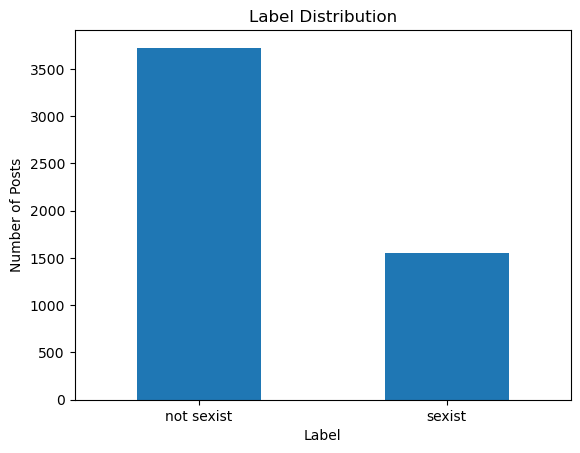

In [42]:
label_counts = data["label"].value_counts()
label_counts.plot(kind="bar")
plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.show()

# Data Preprocessing
For preprocessing, I kept the cleaning simple and controlled. I lowercased the text, replaced `[URL]` with `url`, replaced `[USER]` with `user`, removed emojis and non-ASCII symbols, and stripped extra spaces from the beginning and end of each post. I did not want to overclean the text. In a task like sexism detection, the exact wording matters. Tone matters. Phrasing matters. Even small words can carry meaning. If I stripped the text down too aggressively, I might remove the very signals the model needs to detect the problem. So the approach here was simple: clean the noise, but do not kill the evidence.

In [28]:
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = text.replace("[url]", " url ")
    text = text.replace("[user]", " user ")
    text = text.encode("ascii", "ignore").decode()
    text = text.strip()
    return text

xTrain = xTrain.apply(clean_text)
xTest = xTest.apply(clean_text)
display(xTrain.head())

0    in nigeria, if you rape a woman, the men rape ...
1                                then, she's a keeper.
2    this is like the metallica video where the poo...
3                                               woman?
4                       i bet she wished she had a gun
Name: text, dtype: object

# Feature Engineering
After preprocessing, I converted the text into numerical features using two methods: Bag-of-Words and TF-IDF. Bag-of-Words is the more direct method. It counts the words and short phrases that appear in each post. It does not try to be clever. It just records what shows up and how often. TF-IDF is a little more selective. It still uses words and short phrases, but it gives more weight to terms that seem more informative across the dataset. Common words matter less, and more distinctive words matter more. For both methods, I used unigrams and bigrams. This allowed the models to look at single words as well as two-word phrases. That is useful because sexism is not always contained in one obvious word. Sometimes the damage is in the phrase, the framing, or the way the sentence turns.

In [29]:
bow_vectorizer = CountVectorizer(ngram_range=(1, 2), max_features=5000)
xTrain_bow = bow_vectorizer.fit_transform(xTrain)
xTest_bow = bow_vectorizer.transform(xTest)
print(xTrain_bow.shape)
print(xTest_bow.shape)

(4193, 5000)
(1086, 5000)


In [30]:
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
xTrain_tfidf = tfidf_vectorizer.fit_transform(xTrain)
xTest_tfidf = tfidf_vectorizer.transform(xTest)
print(xTrain_tfidf.shape)
print(xTest_tfidf.shape)

(4193, 5000)
(1086, 5000)


# Model Selection and Training
I trained three models for each feature engineering method: Logistic Regression, Linear SVM, and Multinomial Naive Bayes. With two feature methods and three models, this gave six total experiments. I chose these models because they are straightforward and fit the scale of the assignment. Logistic Regression is a clean linear classifier. Linear SVM is also strong for text classification because it works well with high-dimensional feature spaces. Multinomial Naive Bayes is a classic text classification model and gives a useful comparison point. Each model was trained only on the training set. The test set was not used during training, feature fitting, or model selection. I wanted to keep the test set sealed off until the end, because once the test set leaks into training, the results stop meaning anything.

In [31]:
bow_log_model = LogisticRegression(max_iter=1000)
bow_log_model.fit(xTrain_bow, yTrain)
bow_log_predictions = bow_log_model.predict(xTest_bow)
bow_log_report = classification_report(yTest, bow_log_predictions, output_dict=True, zero_division=0)
print(classification_report(yTest, bow_log_predictions, zero_division=0))

              precision    recall  f1-score   support

  not sexist       0.83      0.90      0.86       789
      sexist       0.66      0.52      0.58       297

    accuracy                           0.79      1086
   macro avg       0.74      0.71      0.72      1086
weighted avg       0.78      0.79      0.79      1086



In [32]:
bow_svm_model = LinearSVC()
bow_svm_model.fit(xTrain_bow, yTrain)
bow_svm_predictions = bow_svm_model.predict(xTest_bow)
bow_svm_report = classification_report(yTest, bow_svm_predictions, output_dict=True, zero_division=0)
print(classification_report(yTest, bow_svm_predictions, zero_division=0))

              precision    recall  f1-score   support

  not sexist       0.83      0.83      0.83       789
      sexist       0.55      0.56      0.55       297

    accuracy                           0.76      1086
   macro avg       0.69      0.69      0.69      1086
weighted avg       0.76      0.76      0.76      1086



In [33]:
bow_nb_model = MultinomialNB()
bow_nb_model.fit(xTrain_bow, yTrain)
bow_nb_predictions = bow_nb_model.predict(xTest_bow)
bow_nb_report = classification_report(yTest, bow_nb_predictions, output_dict=True, zero_division=0)
print(classification_report(yTest, bow_nb_predictions, zero_division=0))

              precision    recall  f1-score   support

  not sexist       0.83      0.85      0.84       789
      sexist       0.57      0.53      0.55       297

    accuracy                           0.76      1086
   macro avg       0.70      0.69      0.69      1086
weighted avg       0.76      0.76      0.76      1086



In [34]:
tfidf_log_model = LogisticRegression(max_iter=1000)
tfidf_log_model.fit(xTrain_tfidf, yTrain)
tfidf_log_predictions = tfidf_log_model.predict(xTest_tfidf)
tfidf_log_report = classification_report(yTest,tfidf_log_predictions,output_dict=True,zero_division=0)
print(classification_report(yTest, tfidf_log_predictions, zero_division=0))

              precision    recall  f1-score   support

  not sexist       0.78      0.97      0.87       789
      sexist       0.80      0.26      0.39       297

    accuracy                           0.78      1086
   macro avg       0.79      0.62      0.63      1086
weighted avg       0.78      0.78      0.74      1086



In [35]:
tfidf_svm_model = LinearSVC()
tfidf_svm_model.fit(xTrain_tfidf, yTrain)
tfidf_svm_predictions = tfidf_svm_model.predict(xTest_tfidf)
tfidf_svm_report = classification_report(yTest, tfidf_svm_predictions, output_dict=True, zero_division=0)
print(classification_report(yTest, tfidf_svm_predictions, zero_division=0))

              precision    recall  f1-score   support

  not sexist       0.83      0.89      0.86       789
      sexist       0.64      0.52      0.57       297

    accuracy                           0.79      1086
   macro avg       0.74      0.70      0.72      1086
weighted avg       0.78      0.79      0.78      1086



In [36]:
tfidf_nb_model = MultinomialNB()
tfidf_nb_model.fit(xTrain_tfidf, yTrain)
tfidf_nb_predictions = tfidf_nb_model.predict(xTest_tfidf)
tfidf_nb_report = classification_report(yTest, tfidf_nb_predictions, output_dict=True, zero_division=0)
print(classification_report(yTest, tfidf_nb_predictions, zero_division=0))

              precision    recall  f1-score   support

  not sexist       0.74      0.99      0.85       789
      sexist       0.84      0.09      0.16       297

    accuracy                           0.75      1086
   macro avg       0.79      0.54      0.51      1086
weighted avg       0.77      0.75      0.66      1086



In [37]:
results = []
results.append({
    "Feature + Model": "Bag-of-Words + Logistic Regression",
    "Sexist (P)": bow_log_report["sexist"]["precision"],
    "Sexist (R)": bow_log_report["sexist"]["recall"],
    "Sexist (F1)": bow_log_report["sexist"]["f1-score"],
    "Non-Sexist (P)": bow_log_report["not sexist"]["precision"],
    "Non-Sexist (R)": bow_log_report["not sexist"]["recall"], 
    "Non-Sexist (F1)": bow_log_report["not sexist"]["f1-score"],
    "Weighted (P)": bow_log_report["weighted avg"]["precision"],
    "Weighted (R)": bow_log_report["weighted avg"]["recall"],
    "Weighted (F1)": bow_log_report["weighted avg"]["f1-score"]  })  

results.append({
    "Feature + Model": "Bag-of-Words + Linear SVM",
    "Sexist (P)": bow_svm_report["sexist"]["precision"],
    "Sexist (R)": bow_svm_report["sexist"]["recall"],
    "Sexist (F1)": bow_svm_report["sexist"]["f1-score"],
    "Non-Sexist (P)": bow_svm_report["not sexist"]["precision"],
    "Non-Sexist (R)": bow_svm_report["not sexist"]["recall"],
    "Non-Sexist (F1)": bow_svm_report["not sexist"]["f1-score"],
    "Weighted (P)": bow_svm_report["weighted avg"]["precision"],
    "Weighted (R)": bow_svm_report["weighted avg"]["recall"],
    "Weighted (F1)": bow_svm_report["weighted avg"]["f1-score"]  })  

results.append({
    "Feature + Model": "Bag-of-Words + Naive Bayes",
    "Sexist (P)": bow_nb_report["sexist"]["precision"],
    "Sexist (R)": bow_nb_report["sexist"]["recall"],
    "Sexist (F1)": bow_nb_report["sexist"]["f1-score"],
    "Non-Sexist (P)": bow_nb_report["not sexist"]["precision"],
    "Non-Sexist (R)": bow_nb_report["not sexist"]["recall"],
    "Non-Sexist (F1)": bow_nb_report["not sexist"]["f1-score"],
    "Weighted (P)": bow_nb_report["weighted avg"]["precision"],
    "Weighted (R)": bow_nb_report["weighted avg"]["recall"], 
    "Weighted (F1)": bow_nb_report["weighted avg"]["f1-score"]  })  

results.append({
    "Feature + Model": "TF-IDF + Logistic Regression",
    "Sexist (P)": tfidf_log_report["sexist"]["precision"],
    "Sexist (R)": tfidf_log_report["sexist"]["recall"],
    "Sexist (F1)": tfidf_log_report["sexist"]["f1-score"],
    "Non-Sexist (P)": tfidf_log_report["not sexist"]["precision"],
    "Non-Sexist (R)": tfidf_log_report["not sexist"]["recall"],
    "Non-Sexist (F1)": tfidf_log_report["not sexist"]["f1-score"],
    "Weighted (P)": tfidf_log_report["weighted avg"]["precision"],
    "Weighted (R)": tfidf_log_report["weighted avg"]["recall"],
    "Weighted (F1)": tfidf_log_report["weighted avg"]["f1-score"]  })

results.append({
    "Feature + Model": "TF-IDF + Linear SVM",
    "Sexist (P)": tfidf_svm_report["sexist"]["precision"],
    "Sexist (R)": tfidf_svm_report["sexist"]["recall"],
    "Sexist (F1)": tfidf_svm_report["sexist"]["f1-score"],
    "Non-Sexist (P)": tfidf_svm_report["not sexist"]["precision"],
    "Non-Sexist (R)": tfidf_svm_report["not sexist"]["recall"],
    "Non-Sexist (F1)": tfidf_svm_report["not sexist"]["f1-score"],
    "Weighted (P)": tfidf_svm_report["weighted avg"]["precision"],
    "Weighted (R)": tfidf_svm_report["weighted avg"]["recall"],
    "Weighted (F1)": tfidf_svm_report["weighted avg"]["f1-score"]  })  

results.append({
    "Feature + Model": "TF-IDF + Naive Bayes",
    "Sexist (P)": tfidf_nb_report["sexist"]["precision"],
    "Sexist (R)": tfidf_nb_report["sexist"]["recall"],
    "Sexist (F1)": tfidf_nb_report["sexist"]["f1-score"],
    "Non-Sexist (P)": tfidf_nb_report["not sexist"]["precision"],
    "Non-Sexist (R)": tfidf_nb_report["not sexist"]["recall"],
    "Non-Sexist (F1)": tfidf_nb_report["not sexist"]["f1-score"],
    "Weighted (P)": tfidf_nb_report["weighted avg"]["precision"],
    "Weighted (R)": tfidf_nb_report["weighted avg"]["recall"],
    "Weighted (F1)": tfidf_nb_report["weighted avg"]["f1-score"]  })  

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Feature + Model,Sexist (P),Sexist (R),Sexist (F1),Non-Sexist (P),Non-Sexist (R),Non-Sexist (F1),Weighted (P),Weighted (R),Weighted (F1)
0,Bag-of-Words + Logistic Regression,0.657,0.522,0.582,0.833,0.897,0.864,0.785,0.795,0.787
1,Bag-of-Words + Linear SVM,0.554,0.556,0.555,0.832,0.831,0.832,0.756,0.756,0.756
2,Bag-of-Words + Naive Bayes,0.571,0.529,0.549,0.827,0.850,0.839,0.757,0.762,0.759
3,TF-IDF + Logistic Regression,0.796,0.263,0.395,0.778,0.975,0.866,0.783,0.780,0.737
4,TF-IDF + Linear SVM,0.643,0.515,0.572,0.830,0.892,0.860,0.779,0.789,0.781
5,TF-IDF + Naive Bayes,0.844,0.091,0.164,0.744,0.994,0.851,0.771,0.747,0.663


In [38]:
sorted_f1_results = results_df.sort_values("Weighted (F1)", ascending=False)
display(sorted_f1_results.round(3))

,Feature + Model,Sexist (P),Sexist (R),Sexist (F1),Non-Sexist (P),Non-Sexist (R),Non-Sexist (F1),Weighted (P),Weighted (R),Weighted (F1)
0,Bag-of-Words + Logistic Regression,0.657,0.522,0.582,0.833,0.897,0.864,0.785,0.795,0.787
4,TF-IDF + Linear SVM,0.643,0.515,0.572,0.830,0.892,0.860,0.779,0.789,0.781
2,Bag-of-Words + Naive Bayes,0.571,0.529,0.549,0.827,0.850,0.839,0.757,0.762,0.759
1,Bag-of-Words + Linear SVM,0.554,0.556,0.555,0.832,0.831,0.832,0.756,0.756,0.756
3,TF-IDF + Logistic Regression,0.796,0.263,0.395,0.778,0.975,0.866,0.783,0.780,0.737
5,TF-IDF + Naive Bayes,0.844,0.091,0.164,0.744,0.994,0.851,0.771,0.747,0.663


# Evaluation and Results

Each model was evaluated on the test set using precision, recall, and F1-score for both classes. I also reported weighted-average precision, recall, and F1-score. I used weighted F1-score as the main comparison metric because the dataset is imbalanced. There are more `not sexist` examples than `sexist` examples, so accuracy by itself would not tell the full story. A model could play it safe, predict the majority class too often, and still look better than it really is. Weighted F1 gives a more honest overall picture. It balances precision and recall while still accounting for how many examples belong to each class.

## Experimental Results

(A table detailed model performance on the test set with at least 6 rows. Report the best performance.)


In [39]:
best_result = sorted_f1_results.iloc[0]
print("Best Model:")
print(best_result["Feature + Model"])
print("Best Weighted F1:")
print(round(best_result["Weighted (F1)"], 3))

Best Model:
Bag-of-Words + Logistic Regression
Best Weighted F1:
0.787


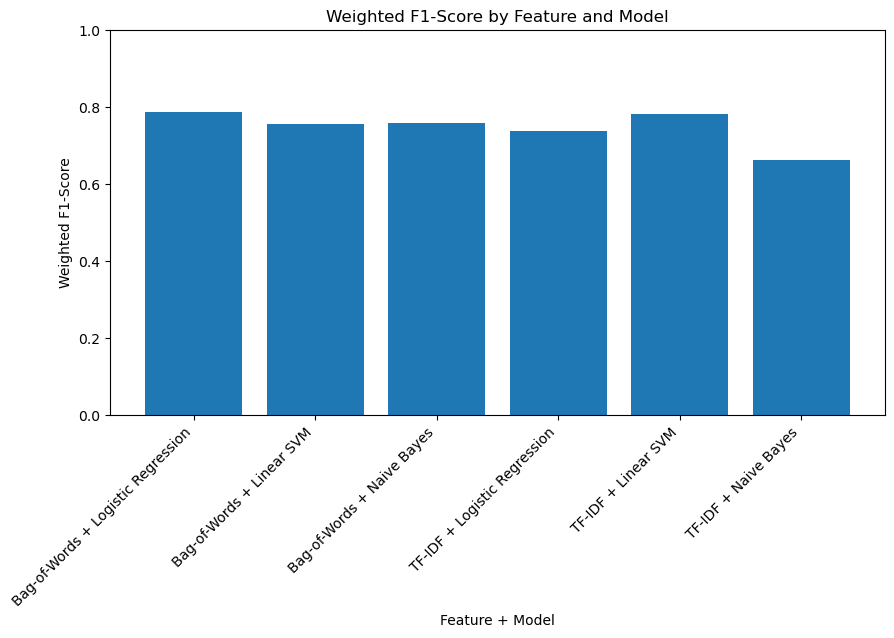

In [41]:
plt.figure(figsize=(10, 5))
plt.bar(results_df["Feature + Model"], results_df["Weighted (F1)"])
plt.title("Weighted F1-Score by Feature and Model")
plt.xlabel("Feature + Model")
plt.ylabel("Weighted F1-Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.show()

# AI Usage & Additional Comments

I did not use AI for coding purposes but rather a quick reminder of how to proceed and explanations (referring to model selection, training purposes, etc). The coding part wasn't an issue but rather how to proceed. I sought to refer to my previous homework entries, but I also believed that my writing conventions seemed a bit too informal when it came to it. I wanted to follow something more direct and straightforward and AI helped me create variable names.

If anything, I have to say that this is not my best work. These past few weeks have not been great and needed to prioritize my well being, get more sleep, etc.. So I will accept that this is pretty substandard code, but hopefully it gets the job done.

## Project Summary
### 1. Data Preprocessing


### 2. Feature Engineering
 

### 3. Model Selection and Architecture


### 4. Training and Validation


### 5. Evaluation and Results


### 6. Use of Generative AI (if you use)